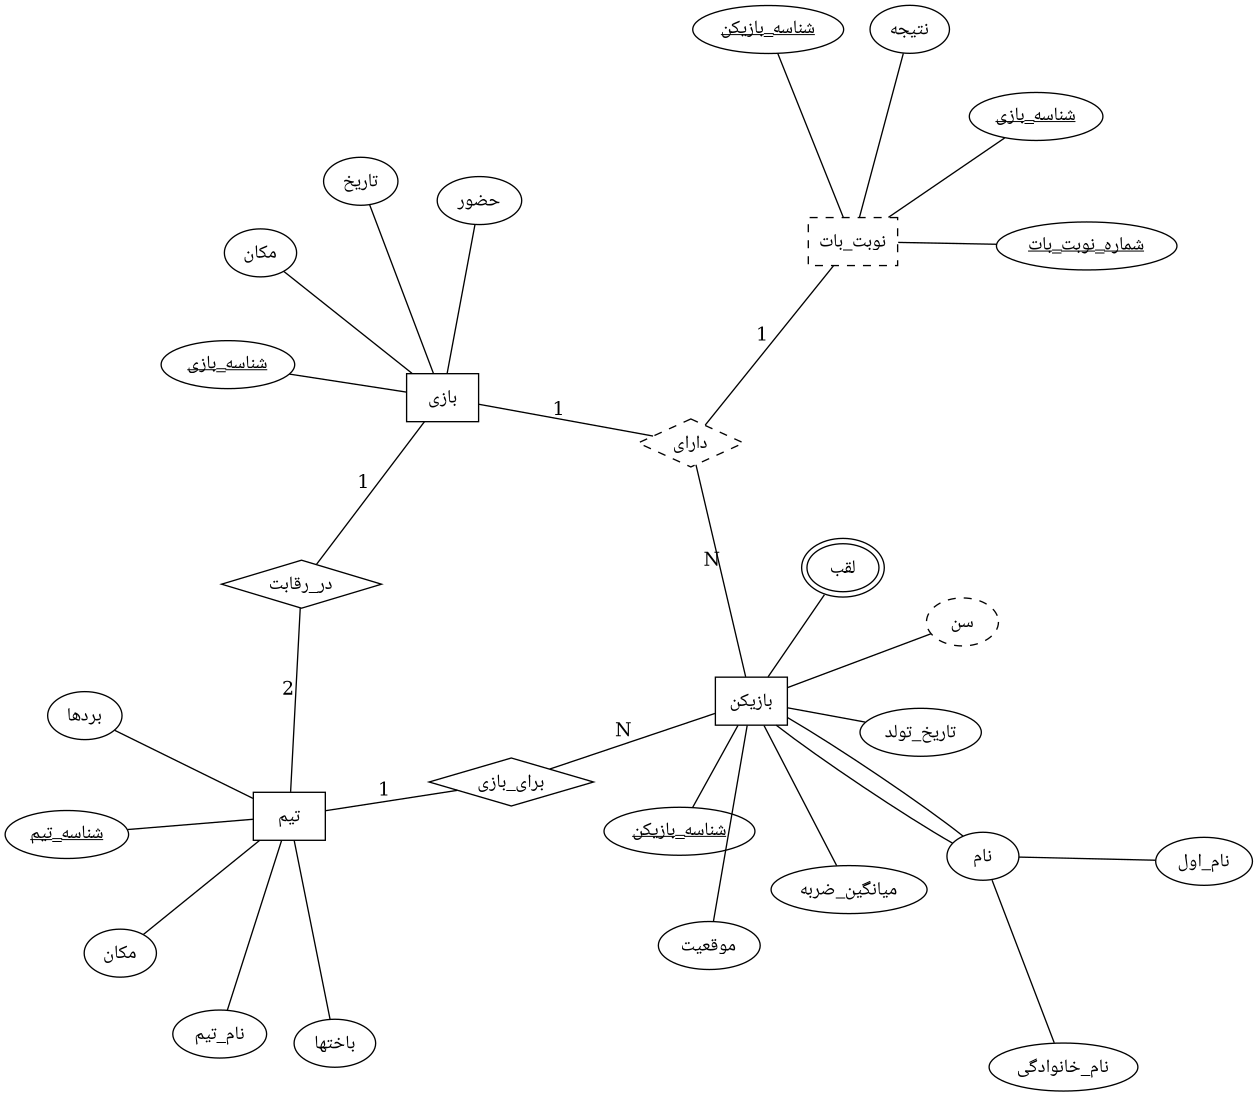

In [9]:
from PIL import Image
import requests
import os

path = '../Dataset/Generated/Graphviz/Graphviz-med-persian/'

img = Image.open(os.path.join(path, 'Baseballgame.png'))

# Display the image (optional)
display(img)

Now, we can use `pytesseract.image_to_data` to extract the text and bounding box information. The `output_type` parameter is set to `pytesseract.Output.DICT` to get the results as a dictionary.

The `data` dictionary contains lists for each type of information extracted (level, page_num, block_num, par_num, line_num, word_num, left, top, width, height, conf, text).

You can iterate through the extracted data to get the text and bounding box for each detected word or line. For example, to print each word and its bounding box:

In [10]:
#!pip install easyocr

In [11]:
import easyocr
import numpy as np
from PIL import ImageDraw

def ocr(img):

    # Create a drawing object on a copy of the original image to avoid modifying the previous result
    img_with_easyocr_boxes = img.copy()
    draw = ImageDraw.Draw(img_with_easyocr_boxes)

    # Initialize the EasyOCR reader
    # Specify the language code for Persian ('fa')
    reader = easyocr.Reader(['fa', 'en']) # You can include 'en' if there might be English text as well

    # Convert the PIL Image to a NumPy array
    img_np = np.array(img)

    # Read text from the image
    # The output is a list of tuples, each containing (bbox, text, confidence)
    easyocr_results = reader.readtext(img_np)
    # Sort results by y-coordinate (top position) of bounding box
    sorted_results = sorted(easyocr_results, key=lambda x: (x[0][0][1], x[0][0][0]))

    # Initialize list for combined results
    combined_results = []
    i = 0
    
    y_threshold=5
    x_threshold=20
    
    while i < len(sorted_results):
        bbox, text, conf = sorted_results[i]
        combined_text = text
        combined_bbox = bbox
        combined_conf = [conf]

        j = i + 1
        while j < len(sorted_results):
            next_bbox, next_text, next_conf = sorted_results[j]

            # Centers for vertical alignment
            curr_y = np.mean([p[1] for p in combined_bbox])
            next_y = np.mean([p[1] for p in next_bbox])
            y_diff = abs(curr_y - next_y)

            # Horizontal gap (can be slightly negative)
            curr_right = max(p[0] for p in combined_bbox)
            next_left = min(p[0] for p in next_bbox)
            
            curr_left = min(p[0] for p in combined_bbox)
            next_right = max(p[0] for p in next_bbox)

            x_gap = min(abs(next_left - curr_right), abs(curr_left - next_right))

            # Merge if same line and horizontally close (allow small overlap)
            if y_diff < y_threshold:

                # draw red line for debugging
                #draw.rectangle([tuple(combined_bbox[0]), tuple(combined_bbox[2])], outline="red", width=5)
                #draw.rectangle([tuple(next_bbox[0]), tuple(next_bbox[2])], outline="red", width=5)

                if x_gap < x_threshold:
                    combined_text += ' ' + next_text
                    combined_bbox = [
                        [min(combined_bbox[0][0], next_bbox[0][0]), min(combined_bbox[0][1], next_bbox[0][1])],
                        [max(combined_bbox[1][0], next_bbox[1][0]), min(combined_bbox[1][1], next_bbox[1][1])],
                        [max(combined_bbox[2][0], next_bbox[2][0]), max(combined_bbox[2][1], next_bbox[2][1])],
                        [min(combined_bbox[3][0], next_bbox[3][0]), max(combined_bbox[3][1], next_bbox[3][1])]
                    ]
                    combined_conf.append(next_conf)
                    j += 1
                else:
                    break
            else:
                break

        combined_results.append((combined_bbox, combined_text.strip(), sum(combined_conf) / len(combined_conf)))
        i = j if j > i + 1 else i + 1

    easyocr_results = combined_results
        
    # Draw bounding boxes from EasyOCR results
    # for (bbox, text, prob) in easyocr_results:
    #     top_left = tuple(bbox[0])
    #     bottom_right = tuple(bbox[2])
    #     draw.rectangle([top_left, bottom_right], outline="blue", width=2)

    # # Display the image with EasyOCR bounding boxes
    # display(img_with_easyocr_boxes)

    return easyocr_results
 
easyocr_results = ocr(img)

The `easyocr_results` variable contains a list of detections. Each detection is a tuple with:

*   `bbox`: The bounding box coordinates (a list of four points).
*   `text`: The extracted text.
*   `prob`: The confidence score for the detection.

You can also visualize these bounding boxes on the image, similar to what we did with Tesseract.

In [12]:
from time import sleep
#!pip install deep-translator
#!pip install googletrans==4.0.0-rc1
from deep_translator import GoogleTranslator

def translator(easyocr_results):
    # Initialize the translator
    translator = GoogleTranslator(source='fa', target='en')
    
    # Batch all texts together for more efficient translation
    texts = [text for (_, text, _) in easyocr_results]
    
    # Translate the extracted text
    translated_results = []
    for i, (bbox, text, prob) in enumerate(easyocr_results):
        # Translate the text to English with error handling
        if text.strip():  # Only translate non-empty strings
            translated_text = translator.translate(text)
            if not translated_text:  # If translation returns empty
                translated_text = text  # Keep original text
        else:
            translated_text = text
        
        translated_results.append((bbox, text, translated_text, prob))
        
        # Add a small delay every few translations to avoid rate limits
        if i % 5 == 0:
            sleep(0.5)        
        
    mapping_json = {
        "original_text": [text for (_, text, _, _) in translated_results],
        "translated_text": [translated_text for (_, _, translated_text, _) in translated_results],
    }

    return mapping_json, translated_results

mapping_json, translated_results = translator(easyocr_results)
# Print the original and translated results
for (bbox, original_text, translated_text, prob) in translated_results:
    print(f"Original Text: {original_text}, Translated Text: {translated_text}, Confidence: {prob:.2f}")

Original Text: شناسه _ بازیکن, Translated Text: Player ID, Confidence: 0.53
Original Text: نتیجه, Translated Text: result, Confidence: 0.72
Original Text: شناسه _باذی, Translated Text: ID _Bazi, Confidence: 0.35
Original Text: تاریخ, Translated Text: date, Confidence: 0.77
Original Text: حضور, Translated Text: presence, Confidence: 1.00
Original Text: نوبت  بات شفارد, Translated Text: It's Shepard's turn, Confidence: 0.25
Original Text: مکان, Translated Text: place, Confidence: 0.58
Original Text: شناسه _باذی, Translated Text: ID _Bazi, Confidence: 0.37
Original Text: بازی, Translated Text: game, Confidence: 0.64
Original Text: در_ رقابت, Translated Text: in competition, Confidence: 0.60
Original Text: بازیکن, Translated Text: the player, Confidence: 0.61
Original Text: _ دها, Translated Text: _ Dozens, Confidence: 0.67
Original Text: تولد تاریخ, Translated Text: Birth date, Confidence: 0.78
Original Text: برای _ بازی, Translated Text: for _ game, Confidence: 0.35
Original Text: شناسه 

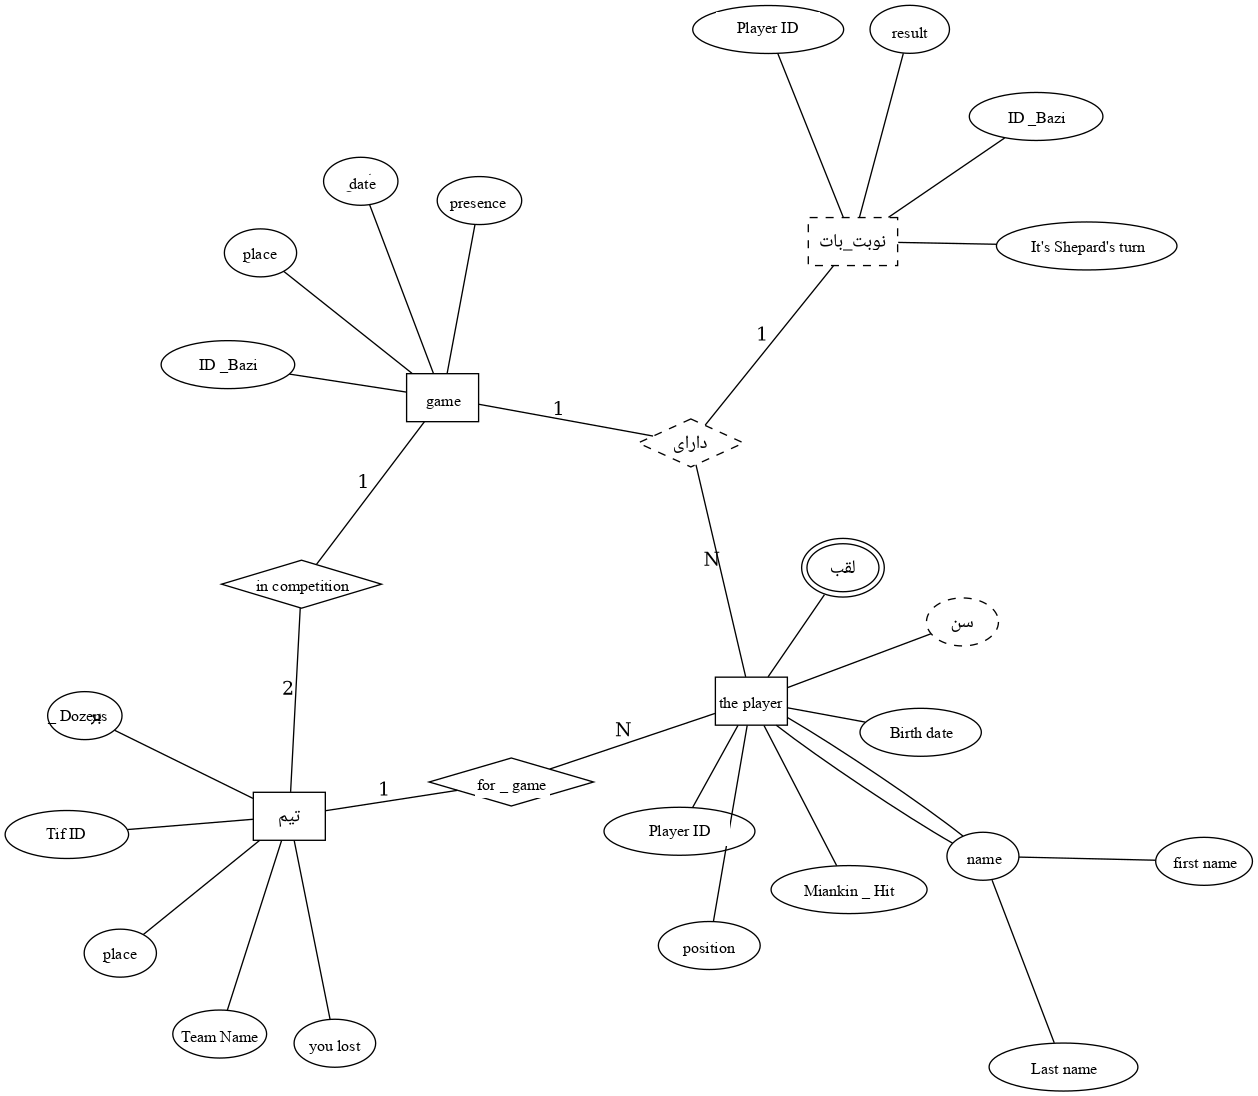

In [13]:
from PIL import ImageDraw, ImageFont

def draw_translated_text(img, translated_results):
    # Create a copy of the original image to draw on
    img_translated_boxes = img.copy()
    draw = ImageDraw.Draw(img_translated_boxes)

    # Define a font and size (increased font size and changed to Times New Roman)
    try:
        # You might need to adjust the font file path depending on the system
        font = ImageFont.truetype("times.ttf", 16) # Increased font size and changed font
    except IOError:
        # Fallback to default font if Times New Roman is not found
        print("Times New Roman font not found. Using default font.")
        font = ImageFont.load_default()

    # Iterate through the translated results
    for (bbox, original_text, translated_text, prob) in translated_results:
        # Get the coordinates of the original bounding box
        # Assuming the bounding box is roughly rectangular for simplicity
        top_left_orig = tuple([bbox[0][0]-1, bbox[0][1]-1])
        bottom_right_orig = tuple([bbox[2][0]+1, bbox[2][1]+1])

        if translated_text == "":
            continue
        # Draw a white rectangle over the original bounding box area to "erase" it
        draw.rectangle([top_left_orig, bottom_right_orig], fill="white", outline=None)

        # Calculate the center of the original bounding box
        center_x = (top_left_orig[0] + bottom_right_orig[0]) / 2
        center_y = (top_left_orig[1] + bottom_right_orig[1]) / 2

        # Draw the translated text
        draw.text((center_x, center_y), translated_text, fill="black", font=font, anchor="mm") # Use anchor="mm" for middle alignment

    return img_translated_boxes

img_translated_boxes = draw_translated_text(img, translated_results)
# Display the image with translated text
display(img_translated_boxes)

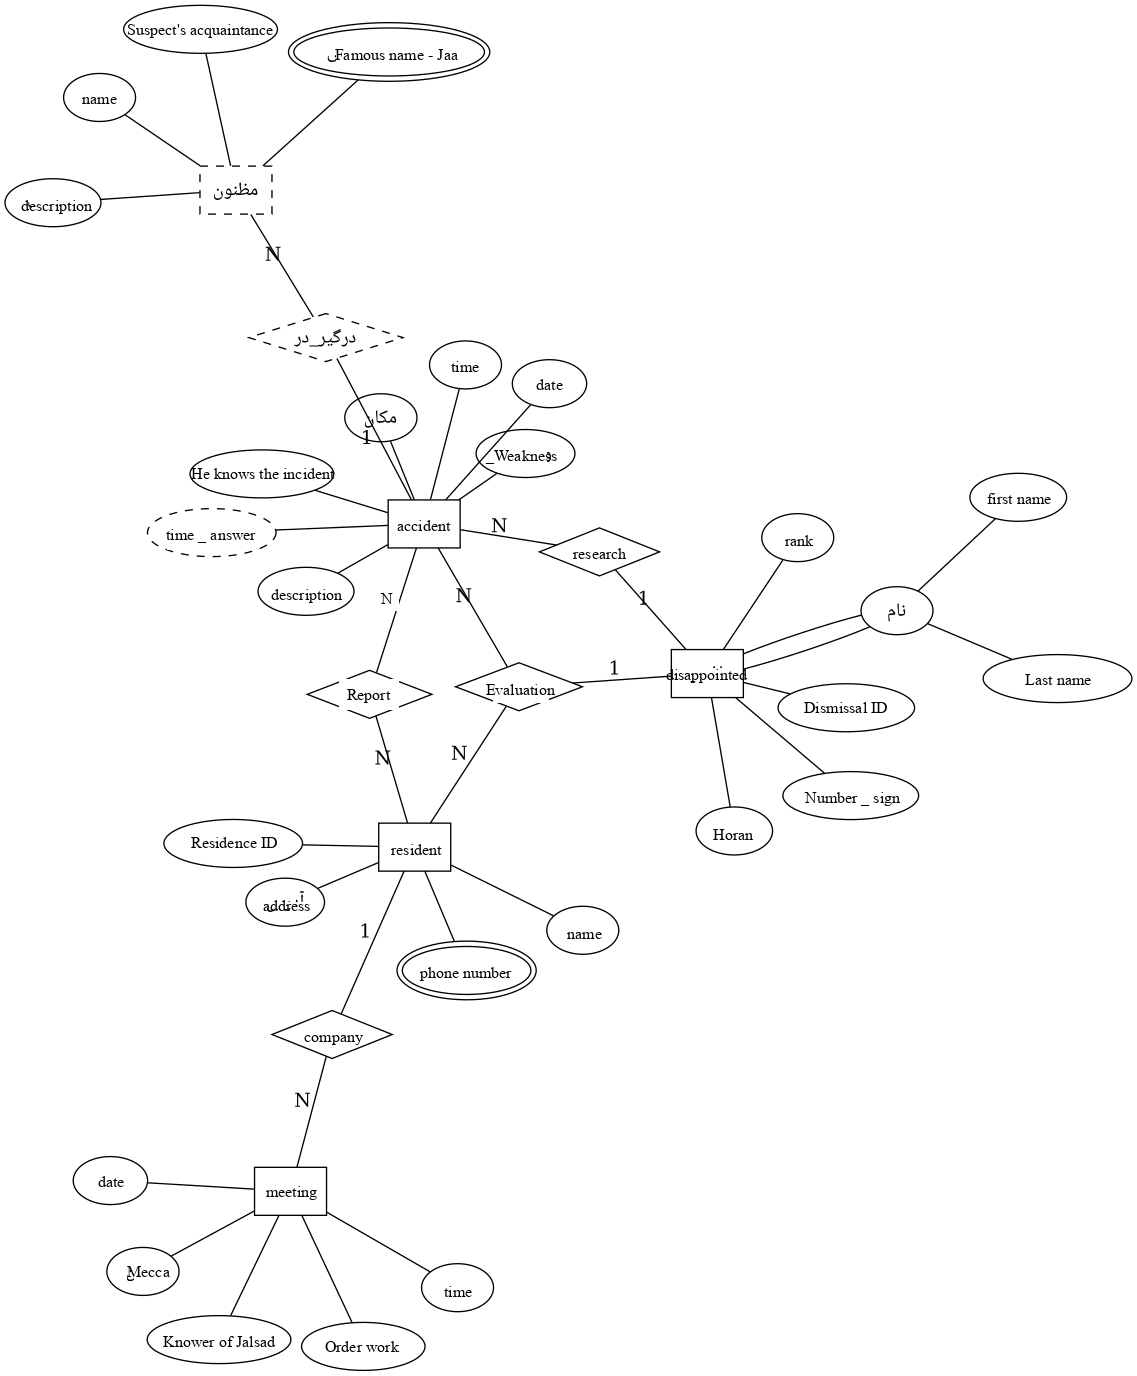

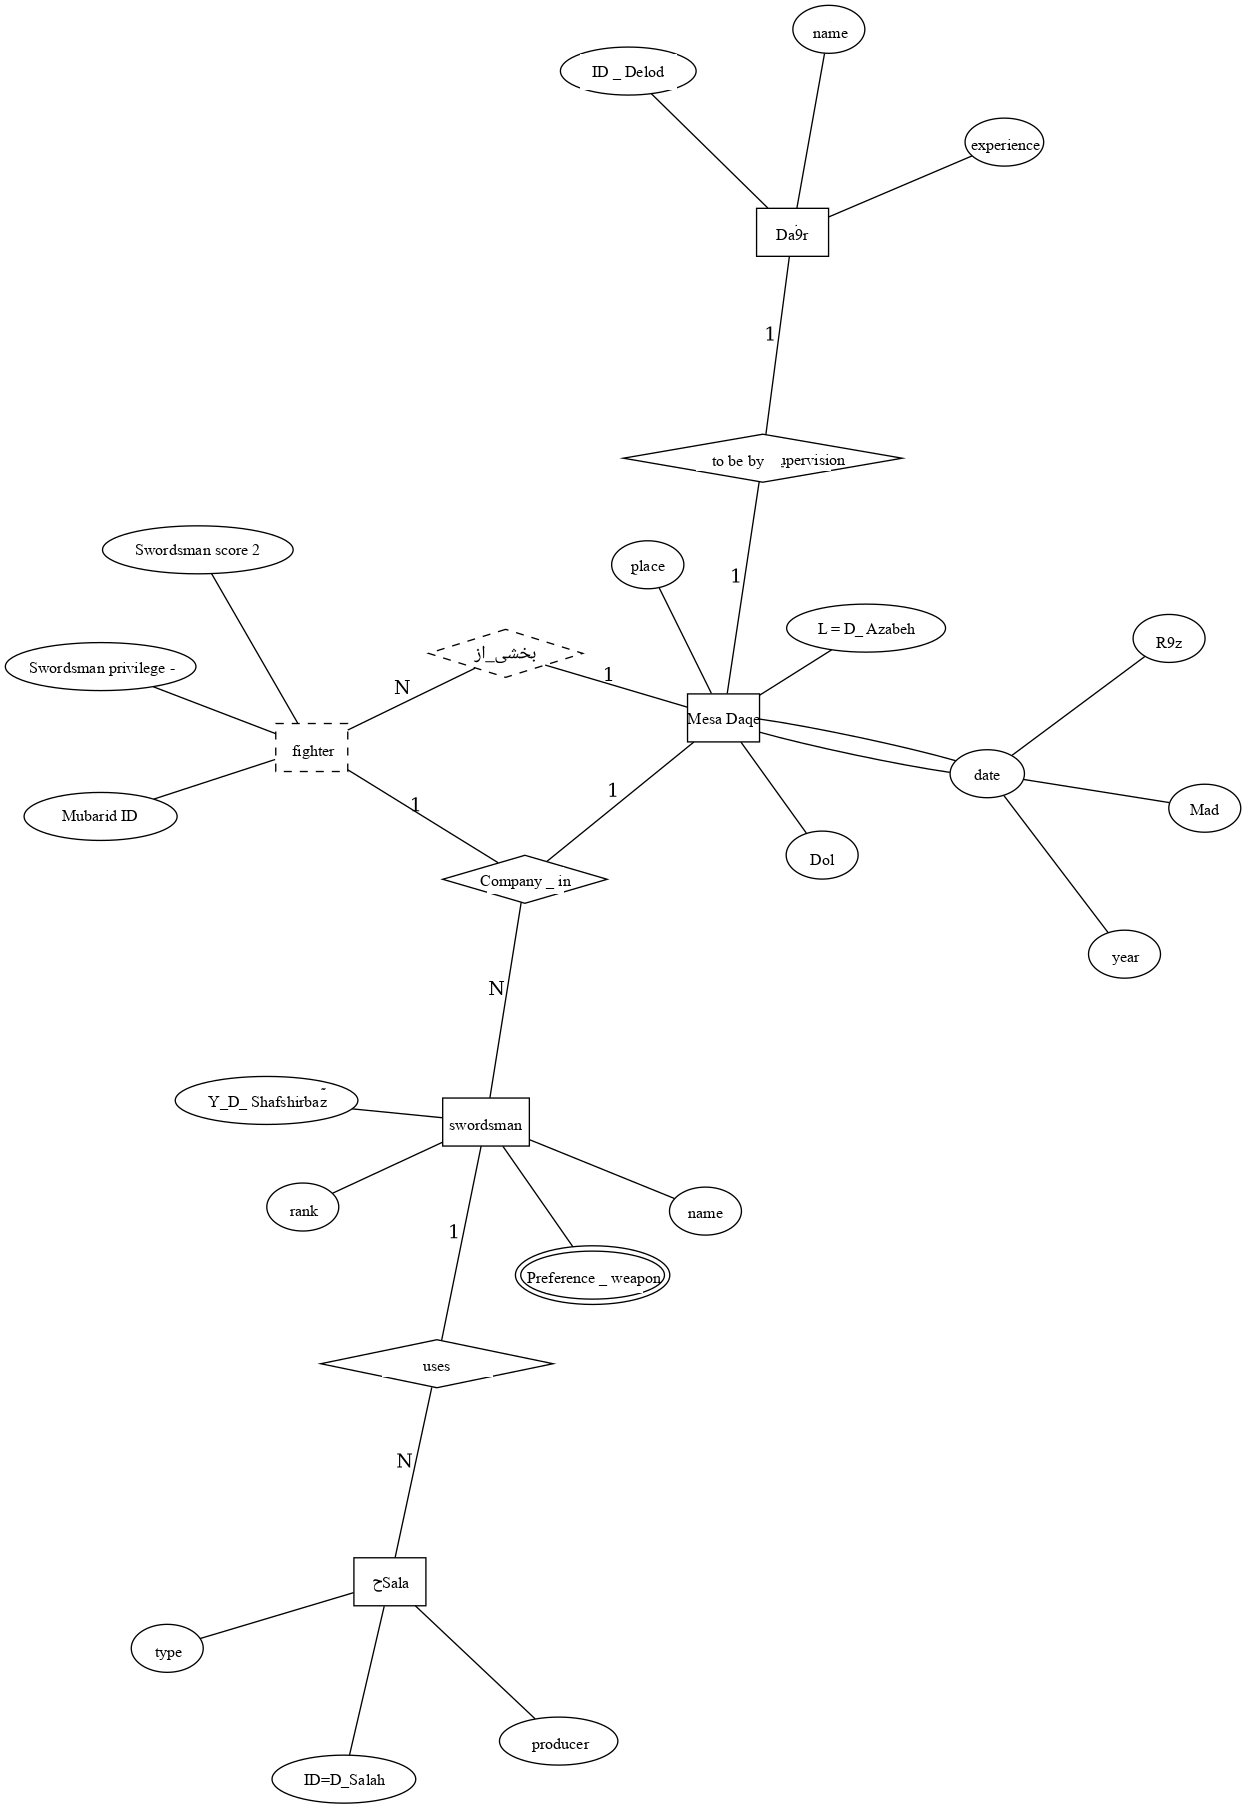

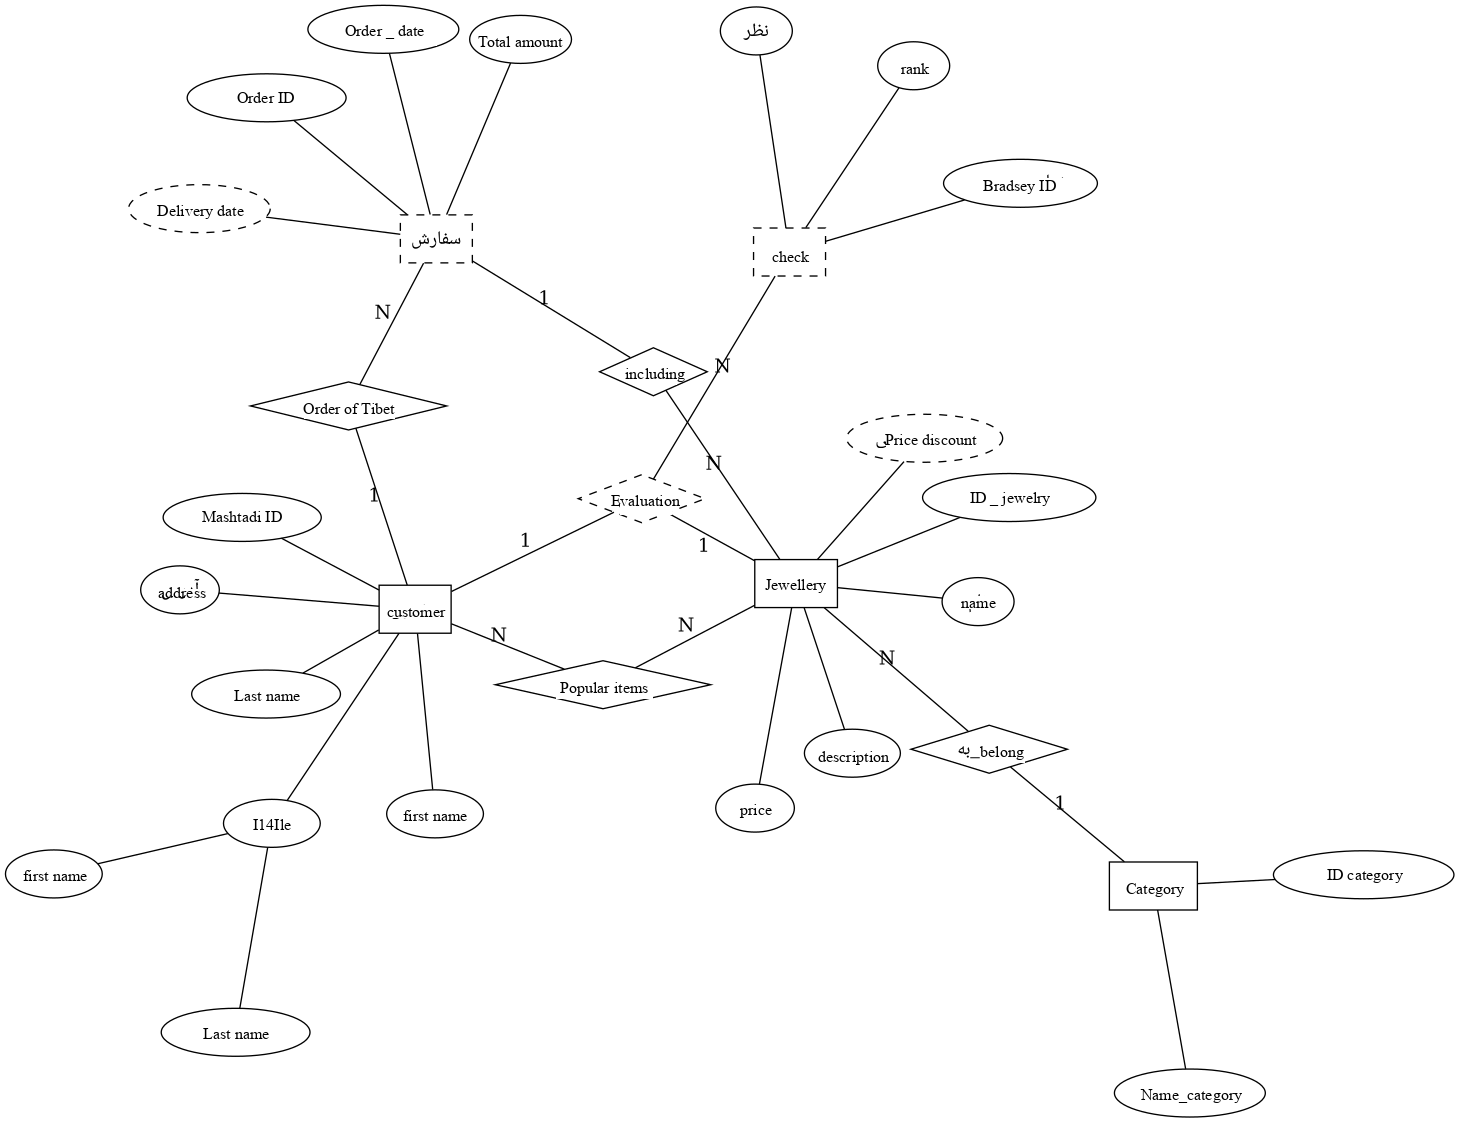

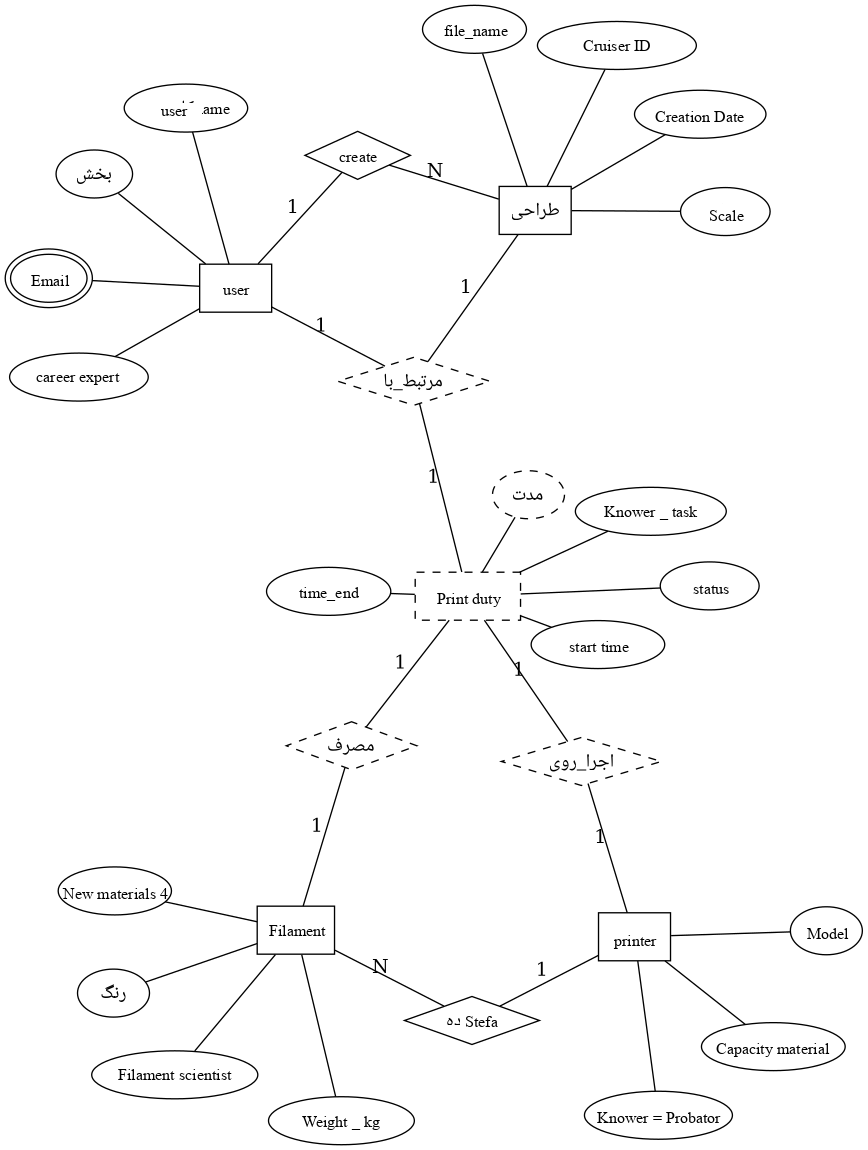

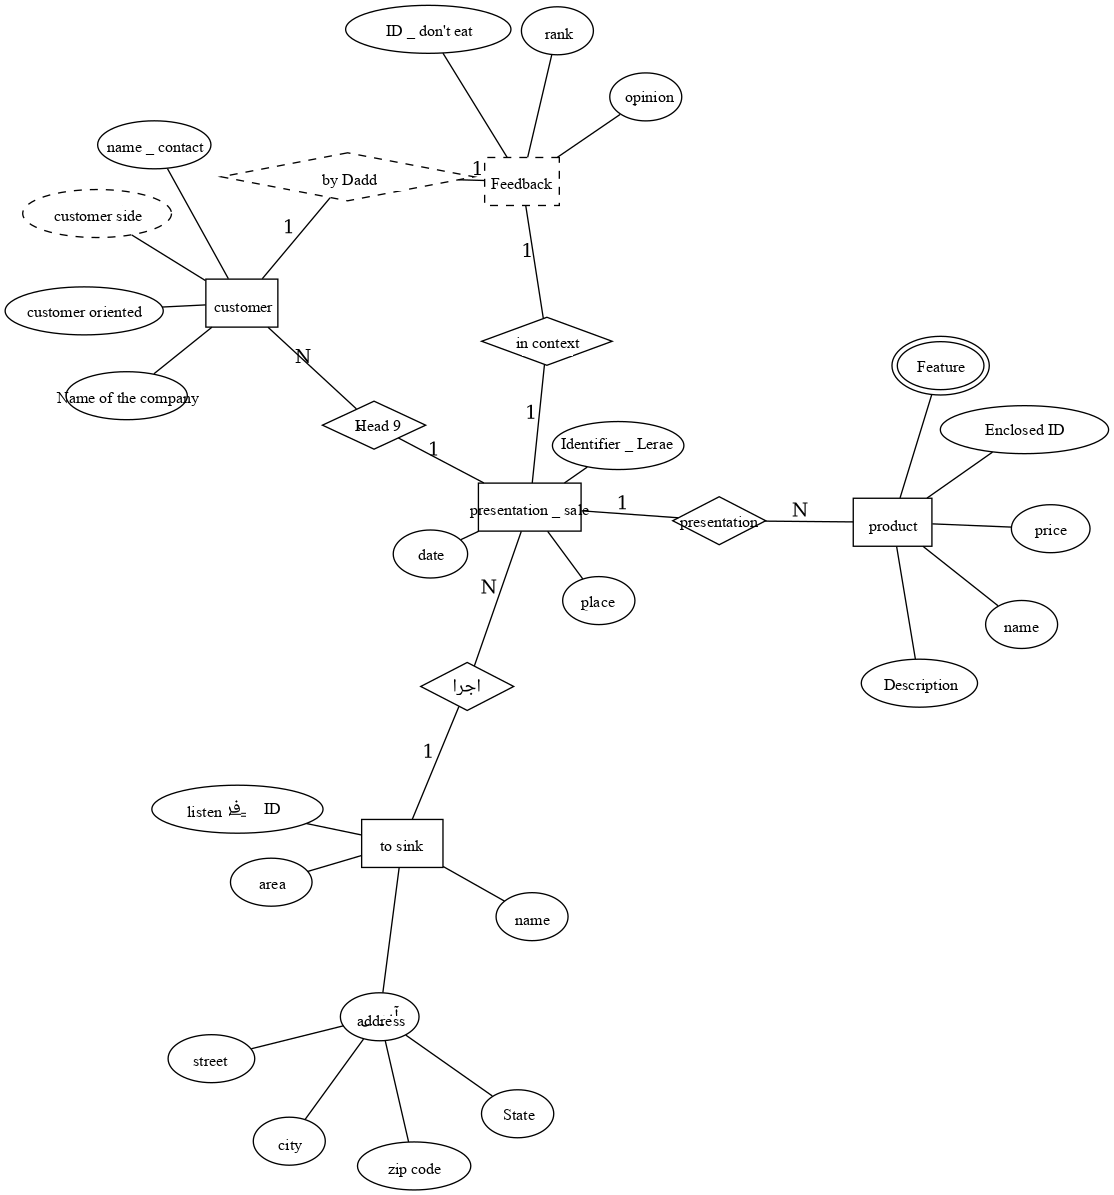

In [ ]:
import os
import json

i = 0

for img_path in os.listdir(path):
    if img_path not in os.listdir('translated'):
        img = Image.open(path + img_path)
        easyocr_results = ocr(img)
        mapping_json, translated_results = translator(easyocr_results)
        img_translated_boxes = draw_translated_text(img, translated_results)
        if i < 5:
            i += 1
            display(img_translated_boxes)
        
        # save the image
        img_translated_boxes.save('translated/' + img_path)
        
        # save the mapping json
        with open('translated-JSON/' + img_path.split('.')[0] + '.json', "w", encoding="utf-8") as f:
            json.dump(mapping_json, f, ensure_ascii=False, indent=4)